In [1]:
import numpy as np, pandas as pd, time, joblib
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

DATA = "../Task-4-Feature-Engineering/"

# 1) Data load
X_train = sparse.load_npz(DATA + "X_train.npz")
y_meta = pd.read_csv(DATA + "y_train_meta.csv")
print(X_train.shape)
print(y_meta.head())
print(y_meta.columns.tolist())

(74992, 1336)
   Unnamed: 0    category domain_feature
0           0  technology      wired.com
1           1  technology        vox.com
2           2        news        vox.com
3           3        news        vox.com
4           4        news        vox.com
['Unnamed: 0', 'category', 'domain_feature']


In [2]:
from sklearn.preprocessing import LabelEncoder

# 2) Target encode + class distribution
y = y_meta["category"].values
print(pd.Series(y).value_counts())

le = LabelEncoder()
y_enc = le.fit_transform(y)
print("Classes:", list(le.classes_))

# 3) 80/20 validation split (stratified)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_enc, test_size=0.2, stratify=y_enc, random_state=42
)
print("Train:", X_tr.shape, "Val:", X_val.shape)

# 4) Majority-class baseline (validation par)
majority = np.bincount(y_tr).argmax()
print("Baseline accuracy:", round(accuracy_score(y_val, np.full_like(y_val, majority)), 4))

# 5) Scaler / X_train ki jaanch
objs = joblib.load(DATA + "fitted_objects.joblib")
print(type(objs))
if isinstance(objs, dict):
    print(list(objs.keys()))

names = pd.read_csv(DATA + "feature_names.csv")
print(names.shape)
print(names.head(3))

num = X_train[:, :36].toarray()
print("First 36 cols  min:", num.min().round(2), " max:", num.max().round(2))
print("Mean of first 5 cols:", num.mean(axis=0)[:5].round(2))
print("Std of first 5 cols:", num.std(axis=0)[:5].round(2))

politics      26695
news          23565
technology    19009
health         2212
energy         1985
market         1152
stocks          374
Name: count, dtype: int64
Classes: ['energy', 'health', 'market', 'news', 'politics', 'stocks', 'technology']
Train: (59993, 1336) Val: (14999, 1336)
Baseline accuracy: 0.356
<class 'dict'>
['title_tfidf', 'title_selector', 'body_tfidf', 'chi2_sel', 'boiler_set', 'num_scaler', 'domain_ohe']
(1336, 1)
                       0
0       title_char_count
1       title_word_count
2  title_avg_word_length
First 36 cols  min: 0.0  max: 5250.0
Mean of first 5 cols: [70.36 11.61  4.88  0.76  5.57]
Std of first 5 cols: [17.92  3.09  0.82  1.61  3.78]


In [3]:
from sklearn.metrics import classification_report, confusion_matrix

scaler = objs["num_scaler"]
print("Scaler features:", getattr(scaler, "n_features_in_", "?"))

def scale_num(X):
    X = X.tocsr()
    num = scaler.transform(X[:, :36].toarray())
    return sparse.hstack([sparse.csr_matrix(num), X[:, 36:]]).tocsr()

# Sanity check: scaled mean ~0, std ~1 hona chahiye
chk = scale_num(X_train)[:, :36].toarray()
print("After scaling  mean:", chk.mean().round(3), " std:", chk.std(axis=0).mean().round(3))

Xs_tr  = scale_num(X_tr)
Xs_val = scale_num(X_val)

results = []

def evaluate(name, model, Xa, Xb):
    t = time.time()
    model.fit(Xa, y_tr)
    train_time = time.time() - t
    pred = model.predict(Xb)
    acc = accuracy_score(y_val, pred)
    mf1 = f1_score(y_val, pred, average="macro")
    wf1 = f1_score(y_val, pred, average="weighted")
    results.append({"Model": name, "Val Accuracy": round(acc, 4),
                    "Macro F1": round(mf1, 4), "Weighted F1": round(wf1, 4),
                    "Train time (s)": round(train_time, 1)})
    print(classification_report(y_val, pred, target_names=le.classes_, digits=3))
    print(confusion_matrix(y_val, pred))
    return pred

# Logistic Regression
log = LogisticRegression(max_iter=1000, class_weight="balanced", n_jobs=-1)
pred_log = evaluate("Logistic Regression", log, Xs_tr, Xs_val)
pd.DataFrame(results)

Scaler features: 36
After scaling  mean: -0.0  std: 1.0


c:\Users\SamTech\Desktop\new-scrape\Task-5-Model-Training\venv_task5\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


              precision    recall  f1-score   support

      energy      0.589     0.902     0.712       397
      health      0.639     0.871     0.737       443
      market      0.513     0.835     0.636       230
        news      0.846     0.857     0.852      4713
    politics      0.959     0.865     0.909      5339
      stocks      0.317     0.760     0.447        75
  technology      0.922     0.884     0.903      3802

    accuracy                          0.867     14999
   macro avg      0.684     0.853     0.742     14999
weighted avg      0.885     0.867     0.873     14999

[[ 358    2    2   15   13    0    7]
 [   2  386    1   43    6    2    3]
 [   2    1  192   23    5    3    4]
 [  82  142   48 4040  131   57  213]
 [ 126   51  111  344 4616   35   56]
 [   0    0    4   10    3   57    1]
 [  38   22   16  298   40   26 3362]]


,Model,Val Accuracy,Macro F1,Weighted F1,Train time (s)
0,Logistic Regression,0.8675,0.7424,0.8728,33.7


lenear model 

In [4]:
from sklearn.svm import LinearSVC

svc = LinearSVC(class_weight="balanced", C=1.0, max_iter=5000, random_state=42)
pred_svc = evaluate("Linear SVM (LinearSVC)", svc, Xs_tr, Xs_val)
pd.DataFrame(results)

              precision    recall  f1-score   support

      energy      0.726     0.861     0.788       397
      health      0.757     0.815     0.785       443
      market      0.650     0.800     0.717       230
        news      0.853     0.901     0.876      4713
    politics      0.960     0.906     0.932      5339
      stocks      0.520     0.693     0.594        75
  technology      0.935     0.898     0.916      3802

    accuracy                          0.896     14999
   macro avg      0.772     0.839     0.801     14999
weighted avg      0.901     0.896     0.897     14999

[[ 342    1    3   23   22    0    6]
 [   3  361    0   63   13    0    3]
 [   2    0  184   30    8    3    3]
 [  37   74   28 4246  126   25  177]
 [  66   26   55  295 4838   13   46]
 [   0    0    4   16    1   52    2]
 [  21   15    9  304   33    7 3413]]


,Model,Val Accuracy,Macro F1,Weighted F1,Train time (s)
0,Logistic Regression,0.8675,0.7424,0.8728,33.7
1,Linear SVM (LinearSVC),0.8958,0.8013,0.8974,84.3


In [5]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(class_weight="balanced", max_depth=30,
                            min_samples_leaf=5, random_state=42)
pred_dt = evaluate("Decision Tree", dt, X_tr, X_val)
pd.DataFrame(results)

              precision    recall  f1-score   support

      energy      0.347     0.564     0.430       397
      health      0.406     0.668     0.505       443
      market      0.271     0.487     0.348       230
        news      0.645     0.788     0.709      4713
    politics      0.890     0.694     0.780      5339
      stocks      0.244     0.520     0.332        75
  technology      0.842     0.693     0.760      3802

    accuracy                          0.715     14999
   macro avg      0.521     0.631     0.552     14999
weighted avg      0.759     0.715     0.727     14999

[[ 224   17   16   49   62    5   24]
 [  12  296    3   91   23    2   16]
 [  14    5  112   42   41    4   12]
 [ 109  222   63 3714  239   38  328]
 [ 206  130  165  981 3706   43  108]
 [   3    4    7   11    6   39    5]
 [  77   55   48  869   89   29 2635]]


,Model,Val Accuracy,Macro F1,Weighted F1,Train time (s)
0,Logistic Regression,0.8675,0.7424,0.8728,33.7
1,Linear SVM (LinearSVC),0.8958,0.8013,0.8974,84.3
2,Decision Tree,0.7151,0.5521,0.7266,63.2


In [6]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                            min_samples_leaf=2, n_jobs=-1, random_state=42)
pred_rf = evaluate("Random Forest", rf, X_tr, X_val)
pd.DataFrame(results)

              precision    recall  f1-score   support

      energy      0.734     0.529     0.615       397
      health      0.702     0.682     0.692       443
      market      0.782     0.404     0.533       230
        news      0.828     0.790     0.808      4713
    politics      0.882     0.917     0.899      5339
      stocks      0.674     0.387     0.492        75
  technology      0.837     0.896     0.865      3802

    accuracy                          0.844     14999
   macro avg      0.777     0.658     0.701     14999
weighted avg      0.842     0.844     0.841     14999

[[ 210    1    3   50  102    0   31]
 [   0  302    0   94   27    0   20]
 [   7    0   93   44   77    0    9]
 [  22   84    7 3723  360    5  512]
 [  31   24   12  285 4898    7   82]
 [   0    0    3   22   13   29    8]
 [  16   19    1  280   79    2 3405]]


,Model,Val Accuracy,Macro F1,Weighted F1,Train time (s)
0,Logistic Regression,0.8675,0.7424,0.8728,33.7
1,Linear SVM (LinearSVC),0.8958,0.8013,0.8974,84.3
2,Decision Tree,0.7151,0.5521,0.7266,63.2
3,Random Forest,0.8441,0.7006,0.8408,163.8


In [7]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1)
pred_knn = evaluate("KNN (k=5)", knn, Xs_tr, Xs_val)
pd.DataFrame(results)

              precision    recall  f1-score   support

      energy      0.107     0.015     0.026       397
      health      0.106     0.025     0.040       443
      market      0.277     0.078     0.122       230
        news      0.504     0.577     0.538      4713
    politics      0.682     0.728     0.704      5339
      stocks      0.296     0.107     0.157        75
  technology      0.599     0.576     0.587      3802

    accuracy                          0.589     14999
   macro avg      0.367     0.301     0.311     14999
weighted avg      0.565     0.589     0.573     14999

[[   6    3    6  142  150    1   89]
 [   1   11    2  215  150    1   63]
 [   7    0   18   79   90    4   32]
 [  14   44   15 2719  983    2  936]
 [  19   35   16 1048 3888    5  328]
 [   0    0    5   20   23    8   19]
 [   9   11    3 1167  415    6 2191]]


,Model,Val Accuracy,Macro F1,Weighted F1,Train time (s)
0,Logistic Regression,0.8675,0.7424,0.8728,33.7
1,Linear SVM (LinearSVC),0.8958,0.8013,0.8974,84.3
2,Decision Tree,0.7151,0.5521,0.7266,63.2
3,Random Forest,0.8441,0.7006,0.8408,163.8
4,KNN (k=5),0.5894,0.3108,0.5733,0.1


In [8]:
from sklearn.svm import SVC

sub_idx, _ = train_test_split(np.arange(Xs_tr.shape[0]), train_size=15000,
                              stratify=y_tr, random_state=42)

svc_rbf = SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=42)
t = time.time()
svc_rbf.fit(Xs_tr[sub_idx], y_tr[sub_idx])
train_time = time.time() - t
pred_rbf = svc_rbf.predict(Xs_val)

acc = accuracy_score(y_val, pred_rbf)
mf1 = f1_score(y_val, pred_rbf, average="macro")
wf1 = f1_score(y_val, pred_rbf, average="weighted")
results.append({"Model": "SVM (RBF, 15k subsample)", "Val Accuracy": round(acc, 4),
                "Macro F1": round(mf1, 4), "Weighted F1": round(wf1, 4),
                "Train time (s)": round(train_time, 1)})
print(classification_report(y_val, pred_rbf, target_names=le.classes_, digits=3))
print(confusion_matrix(y_val, pred_rbf))
pd.DataFrame(results)

              precision    recall  f1-score   support

      energy      0.253     0.476     0.330       397
      health      0.192     0.508     0.279       443
      market      0.158     0.400     0.226       230
        news      0.632     0.465     0.536      4713
    politics      0.835     0.680     0.749      5339
      stocks      0.139     0.347     0.198        75
  technology      0.653     0.773     0.708      3802

    accuracy                          0.619     14999
   macro avg      0.409     0.521     0.432     14999
weighted avg      0.677     0.619     0.636     14999

[[ 189   16   16   53   59    4   60]
 [  19  225   18   96   35    4   46]
 [  22   10   92   41   25   14   26]
 [ 197  503  134 2191  471   47 1170]
 [ 204  299  246  660 3628   55  247]
 [   5    3    8   16    4   26   13]
 [ 111  113   69  412  122   37 2938]]


,Model,Val Accuracy,Macro F1,Weighted F1,Train time (s)
0,Logistic Regression,0.8675,0.7424,0.8728,33.7
1,Linear SVM (LinearSVC),0.8958,0.8013,0.8974,84.3
2,Decision Tree,0.7151,0.5521,0.7266,63.2
3,Random Forest,0.8441,0.7006,0.8408,163.8
4,KNN (k=5),0.5894,0.3108,0.5733,0.1
5,"SVM (RBF, 15k subsample)",0.6193,0.4324,0.6359,347.3


In [9]:
from autogluon.tabular import TabularPredictor

cols = [f"f{i}" for i in range(X_tr.shape[1])]
df_tr = pd.DataFrame(X_tr.toarray().astype("float32"), columns=cols)
df_tr["category"] = le.inverse_transform(y_tr)
df_val = pd.DataFrame(X_val.toarray().astype("float32"), columns=cols)

t = time.time()
predictor = TabularPredictor(label="category", eval_metric="f1_macro",
                             path="outputs/autogluon").fit(
    df_tr, time_limit=900, presets="medium_quality",
    excluded_model_types=["KNN", "NN_TORCH", "FASTAI"])
ag_time = time.time() - t

pred_ag = predictor.predict(df_val)
pred_ag_enc = le.transform(pred_ag)
acc = accuracy_score(y_val, pred_ag_enc)
mf1 = f1_score(y_val, pred_ag_enc, average="macro")
wf1 = f1_score(y_val, pred_ag_enc, average="weighted")
results.append({"Model": "AutoGluon (15 min)", "Val Accuracy": round(acc, 4),
                "Macro F1": round(mf1, 4), "Weighted F1": round(wf1, 4),
                "Train time (s)": round(ag_time, 1)})
print(classification_report(y_val, pred_ag_enc, target_names=le.classes_, digits=3))
print(predictor.leaderboard(silent=True).head(10))
pd.DataFrame(results)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.7
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26300
CPU Count:          8
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       2.60 GB / 15.39 GB (16.9%)
Disk Space Avail:   22.66 GB / 242.88 GB (9.3%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 900s
AutoGluon will save models to "c:\Users\SamTech\Desktop\new-scrape\Task-5-Model-Training\outputs\autogluon"
Train Data Rows:    59993
Train Data Columns: 1336
Label Column:       category
AutoGluon infers your prediction problem is: 'multiclass' (because dtype of label-column == object).
	7 unique label values:  ['news', 'politics', 'technology', 'health', 'market', 'stocks', 'energy']
	If 'multiclass' is not the correct problem_type, plea

              precision    recall  f1-score   support

      energy      0.811     0.693     0.747       397
      health      0.830     0.693     0.755       443
      market      0.832     0.561     0.670       230
        news      0.843     0.893     0.867      4713
    politics      0.927     0.930     0.928      5339
      stocks      0.775     0.413     0.539        75
  technology      0.919     0.904     0.911      3802

    accuracy                          0.890     14999
   macro avg      0.848     0.727     0.774     14999
weighted avg      0.890     0.890     0.889     14999

                 model  score_val eval_metric  pred_time_val    fit_time  \
0           LightGBMXT   0.809156    f1_macro       0.229377  125.510658   
1  WeightedEnsemble_L2   0.809156    f1_macro       0.237605  126.066319   
2             LightGBM   0.776842    f1_macro       0.253192  209.344988   

   pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  \
0                0.229377 

,Model,Val Accuracy,Macro F1,Weighted F1,Train time (s)
0,Logistic Regression,0.8675,0.7424,0.8728,33.7
1,Linear SVM (LinearSVC),0.8958,0.8013,0.8974,84.3
2,Decision Tree,0.7151,0.5521,0.7266,63.2
3,Random Forest,0.8441,0.7006,0.8408,163.8
4,KNN (k=5),0.5894,0.3108,0.5733,0.1
5,"SVM (RBF, 15k subsample)",0.6193,0.4324,0.6359,347.3
6,AutoGluon (15 min),0.8903,0.7741,0.8890,377.6


Test: (19649, 1336)  Classes ok: True
Fit time: 101.6 s
Test accuracy: 0.881
Test macro F1: 0.807
Test weighted F1: 0.8818
              precision    recall  f1-score   support

      energy      0.769     0.800     0.785       546
      health      0.781     0.805     0.793       794
      market      0.650     0.817     0.724       398
        news      0.874     0.928     0.900      8798
    politics      0.932     0.843     0.885      6539
      stocks      0.562     0.804     0.662       179
  technology      0.931     0.873     0.901      2395

    accuracy                          0.881     19649
   macro avg      0.786     0.839     0.807     19649
weighted avg      0.886     0.881     0.882     19649



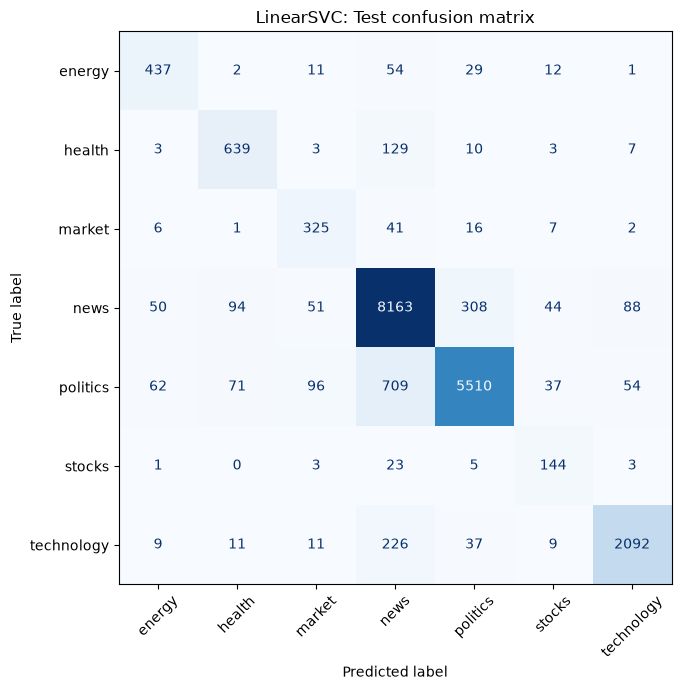

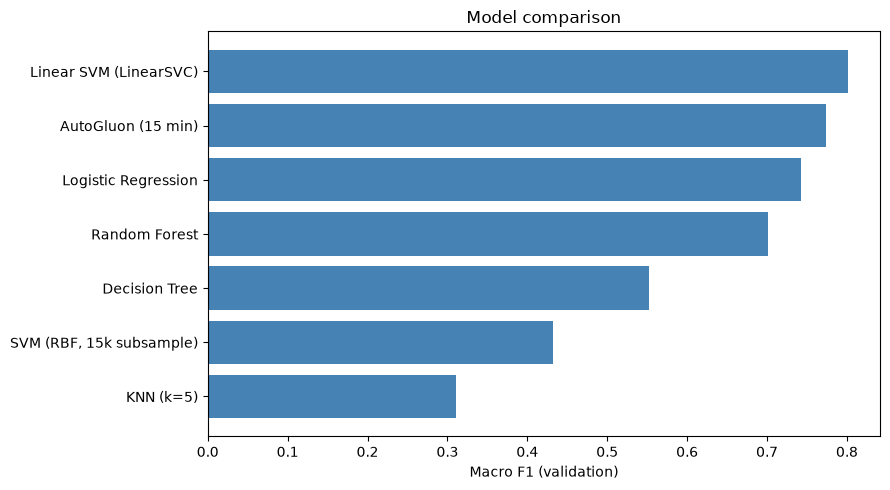

['outputs/linearsvc_final.joblib']

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Test data load
X_test = sparse.load_npz(DATA + "X_test.npz")
y_test_meta = pd.read_csv(DATA + "y_test_meta.csv")
y_test = le.transform(y_test_meta["category"].values)
print("Test:", X_test.shape, " Classes ok:", set(y_test_meta["category"]) <= set(le.classes_))

# Poora train + test ko wahi scaler se scale karo
Xs_full = scale_num(X_train)
Xs_test = scale_num(X_test)

# Final model: poore train par fit
final = LinearSVC(class_weight="balanced", C=1.0, max_iter=5000, random_state=42)
t = time.time()
final.fit(Xs_full, y_enc)
print("Fit time:", round(time.time() - t, 1), "s")

pred_test = final.predict(Xs_test)
print("Test accuracy:", round(accuracy_score(y_test, pred_test), 4))
print("Test macro F1:", round(f1_score(y_test, pred_test, average="macro"), 4))
print("Test weighted F1:", round(f1_score(y_test, pred_test, average="weighted"), 4))
print(classification_report(y_test, pred_test, target_names=le.classes_, digits=3))

# Charts + table save
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=le.classes_,
                                        ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("LinearSVC: Test confusion matrix")
plt.tight_layout(); plt.savefig("outputs/confusion_matrix_test.png", dpi=150); plt.show()

res = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
res.to_csv("outputs/model_comparison_validation.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(res["Model"], res["Macro F1"], color="steelblue")
ax.invert_yaxis(); ax.set_xlabel("Macro F1 (validation)")
ax.set_title("Model comparison")
plt.tight_layout(); plt.savefig("outputs/model_comparison_macro_f1.png", dpi=150); plt.show()
joblib.dump(final, "outputs/linearsvc_final.joblib")

In [11]:
import joblib, numpy as np, pandas as pd
from scipy import sparse

DATA = "../Task-4-Feature-Engineering/"

# Model aur scaler load
model = joblib.load("outputs/linearsvc_final.joblib")
scaler = joblib.load(DATA + "fitted_objects.joblib")["num_scaler"]
classes = np.array(["energy", "health", "market", "news", "politics", "stocks", "technology"])

# Test ke pehle 5 articles
X = sparse.load_npz(DATA + "X_test.npz").tocsr()[:5]
Xs = sparse.hstack([
    sparse.csr_matrix(scaler.transform(X[:, :36].toarray())),
    X[:, 36:]
]).tocsr()

# Predict aur asal labels se compare
predicted = classes[model.predict(Xs)]
actual = pd.read_csv(DATA + "y_test_meta.csv")["category"].values[:5]

print(pd.DataFrame({"Actual": actual, "Predicted": predicted, "Match": actual == predicted}))

     Actual Predicted  Match
0  politics      news  False
1  politics  politics   True
2      news      news   True
3      news      news   True
4      news      news   True
